In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from PIL import Image

import matplotlib as mpl
from pathlib import *

# Read data

In [18]:
# ## Data from Joshua
# # Joshuas Sample 0372 - 1434 HAADF-BF 12.0 Mx STEM HAADF.tif
# atom_label_dict = {
#     'motif_1': {"atom1":"6c3","atom2":"18h","atom3":"18h","atom4":"6c2","atom5":"6c2","atom6":"6c3","atom7":"6c1","atom8":"6c1","atom9":"3a","atom10":"18h","atom11":"18h"},
#     'motif_2': {"atom1":"6c3","atom2":"6c2","atom3":"18h","atom4":"18h","atom5":"6c2","atom6":"6c3","atom7":"6c1","atom8":"3a","atom9":"6c1","atom10":"18h","atom11":"18h"}
# }
# # img_path = r"c:\Users\rejiba\Downloads\0372 - 1434 HAADF-BF 12.0 Mx STEM HAADF.tif"
# img_path = r"I:\from others\vonAnika\12Mx_Statistics\12Mx_Statistics\2026-05-06T14-13-04.342301_TEM_DATA_joshuaspille_0372 - 1434 HAADF-BF 12.0 Mx STEM iFFT(FFT(HAADF))_gamma_changed.tif"

# # img_path = r"I:\from others\vonAnika\Spark_Statistics\Spark_Statistics"
# csv1_path = r"I:\from others\vonAnika\12Mx_Statistics\12Mx_Statistics\Motif_1_local_atom_statistics.csv"
# csv2_path = r"I:\from others\vonAnika\12Mx_Statistics\12Mx_Statistics\Motif_2_local_atom_statistics.csv"
# csv_path = r"I:\from others\vonAnika\12Mx_Statistics\12Mx_Statistics\Full_boundary_atom_statistics.csv"

In [19]:

# Sparks sample TEM_DATA_siyuanzhang_1129 11.0 Mx_crop.

#Spark_Nb51Ni49\0001
atom_label_dict = {
    
    'motif_1': {"0":"18h","1":"18h","2":"6c1","3":"6c3","4":"6c1","5":"6c3","6":"6c2","7":"6c2","8":"3a","9":"18h","10":"18h"},
    # 'motif_2': {"atom1":"6c3","atom2":"6c3","atom3":"6c2","atom4":"6c1","atom5":"6c2","atom6":"6c1","atom7":"3a","atom8":"18h","atom9":"18h","atom10":"18h","atom11":"18h"}
}

#Spark_Nb51Ni49\0005
atom_label_dict = {
    
    'motif_1': {"0":"18h","1":"18h","2":"6c3","3":"6c3","4":"6c1","5":"6c1","6":"6c2","7":"6c2","8":"3a","9":"18h","10":"18h"},
    # 'motif_2': {"atom1":"6c3","atom2":"6c3","atom3":"6c2","atom4":"6c1","atom5":"6c2","atom6":"6c1","atom7":"3a","atom8":"18h","atom9":"18h","atom10":"18h","atom11":"18h"}
}

# csv1_path =r"I:\from others\vonAnika\Spark_Statistics\Spark_Statistics\motif1_local_atom_statistics.csv"
# csv2_path =r"I:\from others\vonAnika\Spark_Statistics\Spark_Statistics\motif2_local_atom_statistics.csv"
results_folder =  Path(r"E:\sciebo\IMM\Cooperations\spark\Spark_Nb51Ni49\0001")
results_folder = Path(r"E:\sciebo\IMM\Cooperations\spark\Spark_Nb51Ni49\0005")
csv_path = results_folder.joinpath("local_atom_statistics.csv")



df = pd.read_csv(csv_path, skiprows=1)
df[['x', 'y']] = df[['x_pos', 'y_pos']]
df["label"] = df["label"].astype("str")
df['label_mu'] = df['label'].map(atom_label_dict["motif_1"])
df


,cell_i,cell_j,atom_id,label,x_pos,y_pos,x_old,y_old,x_unit,y_unit,x,y,label_mu
0,0,0,1,0,2.242217,6.047381,2.420853,6.053591,2.242217,6.047381,2.242217,6.047381,18h
1,0,0,2,1,20.369871,6.484248,20.507877,6.602289,20.369871,6.484248,20.369871,6.484248,18h
2,0,0,3,2,6.244268,14.512186,6.289834,14.481031,6.244268,14.512186,6.244268,14.512186,6c3
3,0,0,4,3,16.136311,-1.775420,16.404781,-1.623007,16.136311,-1.775420,16.136311,-1.775420,6c3
4,0,0,5,4,11.268387,8.966005,11.386735,9.007869,11.268387,8.966005,11.268387,8.966005,6c1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5704,36,15,5705,6,527.858521,510.668884,527.858521,510.668884,26.779789,-1.541692,527.858521,510.668884,6c2
5705,36,15,5706,7,530.705750,521.527405,530.705750,521.527405,29.627005,9.316831,530.705750,521.527405,6c2
5706,36,15,5707,8,529.169495,516.054138,529.169495,516.054138,28.090731,3.843559,529.169495,516.054138,3a
5707,36,15,5708,9,521.684998,510.429382,521.684998,510.429382,20.606234,-1.781201,521.684998,510.429382,18h


In [20]:
atom_label_dict["motif_1"]

{'0': '18h',
 '1': '18h',
 '2': '6c3',
 '3': '6c3',
 '4': '6c1',
 '5': '6c1',
 '6': '6c2',
 '7': '6c2',
 '8': '3a',
 '9': '18h',
 '10': '18h'}

In [21]:
md = pd.read_csv(csv_path, header=None, nrows=1, index_col=0).iloc[:, 0].to_dict()
md

{'nm_per_pixel': 0.0270548924360103}

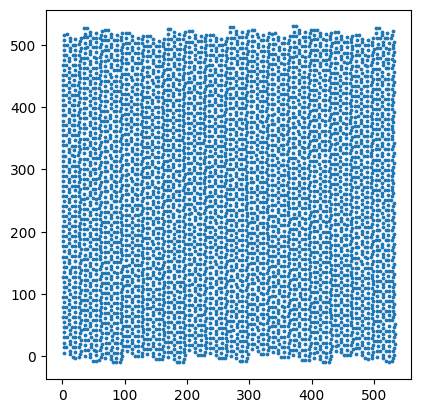

In [22]:
fig,ax = plt.subplots()
ax.scatter(df['x'],df['y'],3)
ax.set_aspect('1')


# Interplanar Spacing

In [23]:
# displacement_trhesold = 1
# # df_rot[df_rot['displacement']<displacement_trhesold].reset_index()
# df_f = df2[df2['x']>500].reset_index()
# fig,ax=plt.subplots()
# ax.scatter(df_f['x'],df_f['y'],3)
# ax.set_aspect(1)


In [24]:
df_rot = df

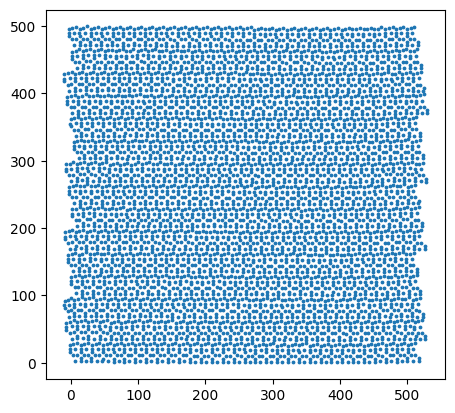

In [25]:
displacement_trhesold = 1
# df_rot[df_rot['displacement']<displacement_trhesold].reset_index()
df_f = df_rot[df_rot['x']<500].reset_index()
fig,ax=plt.subplots()
ax.scatter(df_f['y'],df_f['x'],3)
ax.set_aspect(1)


In [26]:
def get_interplanarSpacings(fixedPos,movingPos,df_rot,mu_c_direction='x',selected_motif='motif_1',max_distance_px=50,displacement_thresold = 1.5 ):
    

    # df_rot = df_rot[df_rot['displacement']<displacement_thresold].reset_index()
    # df_rot = df_rot[df_rot['y']<500].reset_index()
    df_rot_3a = df_rot[df_rot['label_mu'] ==fixedPos]
    selected_site = movingPos
    diff_vals = np.zeros((len(df_rot_3a), len(df_rot)))
    
    # print(df_rot_3a)
    # print(df_rot)
    ## calculate euclididan distance between respetive sites with label fixedPos and movingPos
    for i in range(0, len(df_rot["y"].values)):
        print(df_rot.at[i,'label_mu'])
        print(df_rot.at[i,"motif_source"])
        if df_rot.at[i,"label_mu"]==selected_site: # and df_rot.at[i,"motif_source"]==selected_motif:
            y_3a = df_rot_3a["y"].values
            x_3a = df_rot_3a["x"].values
    
            y = df_rot.at[i, "y"]
            x = df_rot.at[i, "x"]
    
            diff_vals[:,i] = np.sqrt((x_3a - x)**2 + (y_3a -y )**2)
        else:
            diff_vals[:,i] = np.inf

    print(diff_vals)
    min_dist_indices = np.argsort(np.abs(diff_vals), 1)
    # print(min_dist_indices.shape)
    # print(np.abs(diff_vals[min_dist_indices]))

    if movingPos == fixedPos:
        print('same site calculation')
        closest_distances = min_dist_indices[:, 2]
        second_closest_distance = min_dist_indices[:, 3]
    else:
        closest_distances = min_dist_indices[:, 0]
        second_closest_distance = min_dist_indices[:, 1]

    


    ## calculate distance in x or y dircetion
    min_distance_list = []
    df_rot_3a = df_rot_3a.reset_index()
    for i in range(0, len(min_dist_indices)):
        x1 = df_rot.at[closest_distances[i], mu_c_direction]
        x2 = df_rot.at[second_closest_distance[i], mu_c_direction]
        x_3a = df_rot_3a.at[i, mu_c_direction]
        min_distance_list.append(np.mean(np.abs([x_3a - x2, x_3a - x1])))
    
    min_distances = np.array(min_distance_list)
    min_distances = min_distances[min_distances<max_distance_px]
    return min_distances
    # plt.plot(min_distances)
    # min_distances.mean()

In [27]:
def get_interplanarSpacings_wplot(fixedPos,movingPos,df_rot,mu_c_direction='x',selected_motif='motif_1',max_distance_px=50,displacement_thresold = 1.5,plotting=False):
    print(movingPos)
    print(fixedPos)
    # if plotting:

    # df_rot = df_rot[df_rot['displacement']<displacement_thresold].reset_index()
    # df_rot = df_rot[df_rot['y']<500].reset_index()
    df_rot_3a = df_rot[df_rot['label_mu'] ==fixedPos]
    selected_site = movingPos
    diff_vals = np.zeros((len(df_rot_3a), len(df_rot)))
    
    # print(df_rot_3a)
    # print(df_rot)
    ## calculate euclididan distance between respetive sites with label fixedPos and movingPos
    for i in range(0, len(df_rot["y"].values)):
   
        if df_rot.at[i,"label_mu"]==selected_site: # and df_rot.at[i,"motif_source"]==selected_motif:
            # print(df_rot.at[i,'label_mu'])
        # print(df_rot.at[i,"motif_source"])
            y_3a = df_rot_3a["y"].values
            x_3a = df_rot_3a["x"].values
    
            y = df_rot.at[i, "y"]
            x = df_rot.at[i, "x"]
    
            diff_vals[:,i] = np.sqrt((x_3a - x)**2 + (y_3a -y )**2)
            # ax.scatter()
        else:
            diff_vals[:,i] = np.inf

    # print(diff_vals)

    min_dist_indices = np.argsort(np.abs(diff_vals), 1)
    # diff_vals = diff_vals[min_dist_indices]
    # print(min_dist_indices)
    # print(diff_vals[min_dist_indices])

    if movingPos == fixedPos:
        print('same site calculation')
        closest_distances = min_dist_indices[:, 2]
        second_closest_distance = min_dist_indices[:, 3]
    else:
        closest_distances = min_dist_indices[:, 0]
        second_closest_distance = min_dist_indices[:, 1]


    print(movingPos)
    print(fixedPos)


    cmap = mpl.colormaps['prism']
    colors = cmap(np.linspace(0, 1, len(min_dist_indices)))
    ## calculate distance in x or y dircetion
    min_distance_list = []
    print(len(df_rot))
    df_rot_3a = df_rot_3a.reset_index()
    print(closest_distances)

    unique_closest, counts_closest = np.unique(closest_distances, return_counts=True)
    unique_second, counts_second = np.unique(second_closest_distance, return_counts=True)
    
    # print(counts)
    if plotting:
        fig, ax = plt.subplots(figsize=(20,20))
        ax.scatter(df_rot['x'],df_rot['y'],color='gray')
    for i in range(1,len(min_dist_indices)):

        # print(second_closest_distance[i])
        # if any(counts_closest[unique_closest==closest_distances[i]]>1) or any(counts_second[unique_second==second_closest_distance[i]]>1):
        #     continue
        # print([second_closest_distance[i],closest_distances[i]])
        # print()
        x1 = df_rot.at[closest_distances[i], mu_c_direction]
        x2 = df_rot.at[second_closest_distance[i], mu_c_direction]
        x_3a = df_rot_3a.at[i, mu_c_direction]
        # print(closest_distances[i],second_closest_distance[i])

        # diff_c = diff_vals[closest_distances[i],0]
        # diff_sc = diff_vals[second_closest_distance[i],1]

        if np.abs([x_3a - x1])<max_distance_px and  plotting:
            if i==1:
                ax.scatter(df_rot.at[closest_distances[i], 'x'],df_rot.at[closest_distances[i], 'y'],color=colors[i],label=f"{movingPos}, 1st")
                ax.scatter(df_rot.at[second_closest_distance[i], 'x'],df_rot.at[second_closest_distance[i], 'y'],color=colors[i],marker='v',label=f"{movingPos}, 2nd")
                ax.scatter(df_rot_3a.at[i, 'x'], df_rot_3a.at[i, 'y'],color=colors[i],marker='s',label=f"{fixedPos}")
            else:
                ax.scatter(df_rot.at[closest_distances[i], 'x'],df_rot.at[closest_distances[i], 'y'],color=colors[i])
                ax.scatter(df_rot.at[second_closest_distance[i], 'x'],df_rot.at[second_closest_distance[i], 'y'],color=colors[i],marker='v')
                ax.scatter(df_rot_3a.at[i, 'x'], df_rot_3a.at[i, 'y'],color=colors[i],marker='s')
            ax.text(df_rot_3a.at[i, 'x'], df_rot_3a.at[i, 'y'],i)
            ax.text(df_rot.at[closest_distances[i], 'x'],df_rot.at[closest_distances[i], 'y'],i)
            ax.text(df_rot.at[second_closest_distance[i], 'x'],df_rot.at[second_closest_distance[i], 'y'],i)
        # print(len(df_rot_3a.at[i,'x']))
        # min_distance_list.append(np.mean(np.abs([x_3a - x2, x_3a - x1])))
        if fixedPos=='3a':
            # min_distance_list.append(np.(np.abs([x_3a - x2, x_3a - x1])))
            min_distance_list.append((np.abs([x_3a - x1])))
            min_distance_list.append((np.abs([x_3a - x2])))
        else:
            min_distance_list.append(np.mean(np.abs([x_3a - x1])))
        # min_distance_list.append(np.mean(np.abs([x_3a - x2])))
   
        # if i>30:
        #     break
    if plotting:
        ax.legend()
        # ax.set_xlim(0,500)
        # ax.set_ylim(0,500)
        # print(closest_distances)
        ax.set_aspect(1)
    min_distances = np.array(min_distance_list)
    min_distances = min_distances[min_distances<max_distance_px]
    # ax.set_xlim(490,520)
    # ax.set_ylim()
    return min_distances
    # plt.plot(min_distances)
    # min_distances.mean()

In [28]:
df

,cell_i,cell_j,atom_id,label,x_pos,y_pos,x_old,y_old,x_unit,y_unit,x,y,label_mu
0,0,0,1,0,2.242217,6.047381,2.420853,6.053591,2.242217,6.047381,2.242217,6.047381,18h
1,0,0,2,1,20.369871,6.484248,20.507877,6.602289,20.369871,6.484248,20.369871,6.484248,18h
2,0,0,3,2,6.244268,14.512186,6.289834,14.481031,6.244268,14.512186,6.244268,14.512186,6c3
3,0,0,4,3,16.136311,-1.775420,16.404781,-1.623007,16.136311,-1.775420,16.136311,-1.775420,6c3
4,0,0,5,4,11.268387,8.966005,11.386735,9.007869,11.268387,8.966005,11.268387,8.966005,6c1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5704,36,15,5705,6,527.858521,510.668884,527.858521,510.668884,26.779789,-1.541692,527.858521,510.668884,6c2
5705,36,15,5706,7,530.705750,521.527405,530.705750,521.527405,29.627005,9.316831,530.705750,521.527405,6c2
5706,36,15,5707,8,529.169495,516.054138,529.169495,516.054138,28.090731,3.843559,529.169495,516.054138,3a
5707,36,15,5708,9,521.684998,510.429382,521.684998,510.429382,20.606234,-1.781201,521.684998,510.429382,18h


6c2
3a
6c2
3a
5709
[   6   17   28   39   50   61   72   83   94  105  116  127  138  149
  160  171  182  193  204  215  226  237  248  259  270  281  292  303
  314  325  336  347  358  369  380  391  402  413  424  435  446  457
  468  479  490  501  512  523  534  545  556  567  578  589  600  611
  622  633  644  655  666  677  688  699  710  721  732  743  754  765
  776  787  798  809  820  831  842  853  864  875  886  897  908  919
  930  941  952  963  974  985  996 1007 1018 1029 1040 1051 1062 1073
 1084 1095 1106 1117 1128 1139 1150 1161 1172 1183 1194 1205 1216 1227
 1238 1249 1260 1271 1282 1293 1304 1315 1326 1337 1348 1359 1370 1381
 1392 1403 1414 1425 1436 1447 1458 1469 1480 1491 1502 1513 1524 1535
 1546 1557 1568 1579 1590 1601 1612 1623 1634 1645 1656 1667 1678 1689
 1700 1711 1722 1733 1744 1755 1766 1777 1788 1799 1810 1821 1832 1843
 1854 1865 1876 1887 1898 1909 1920 1931 1942 1953 1964 1975 1986 1997
 2008 2019 2030 2041 2052 2063 2074 2085 2096 2107 2118 21

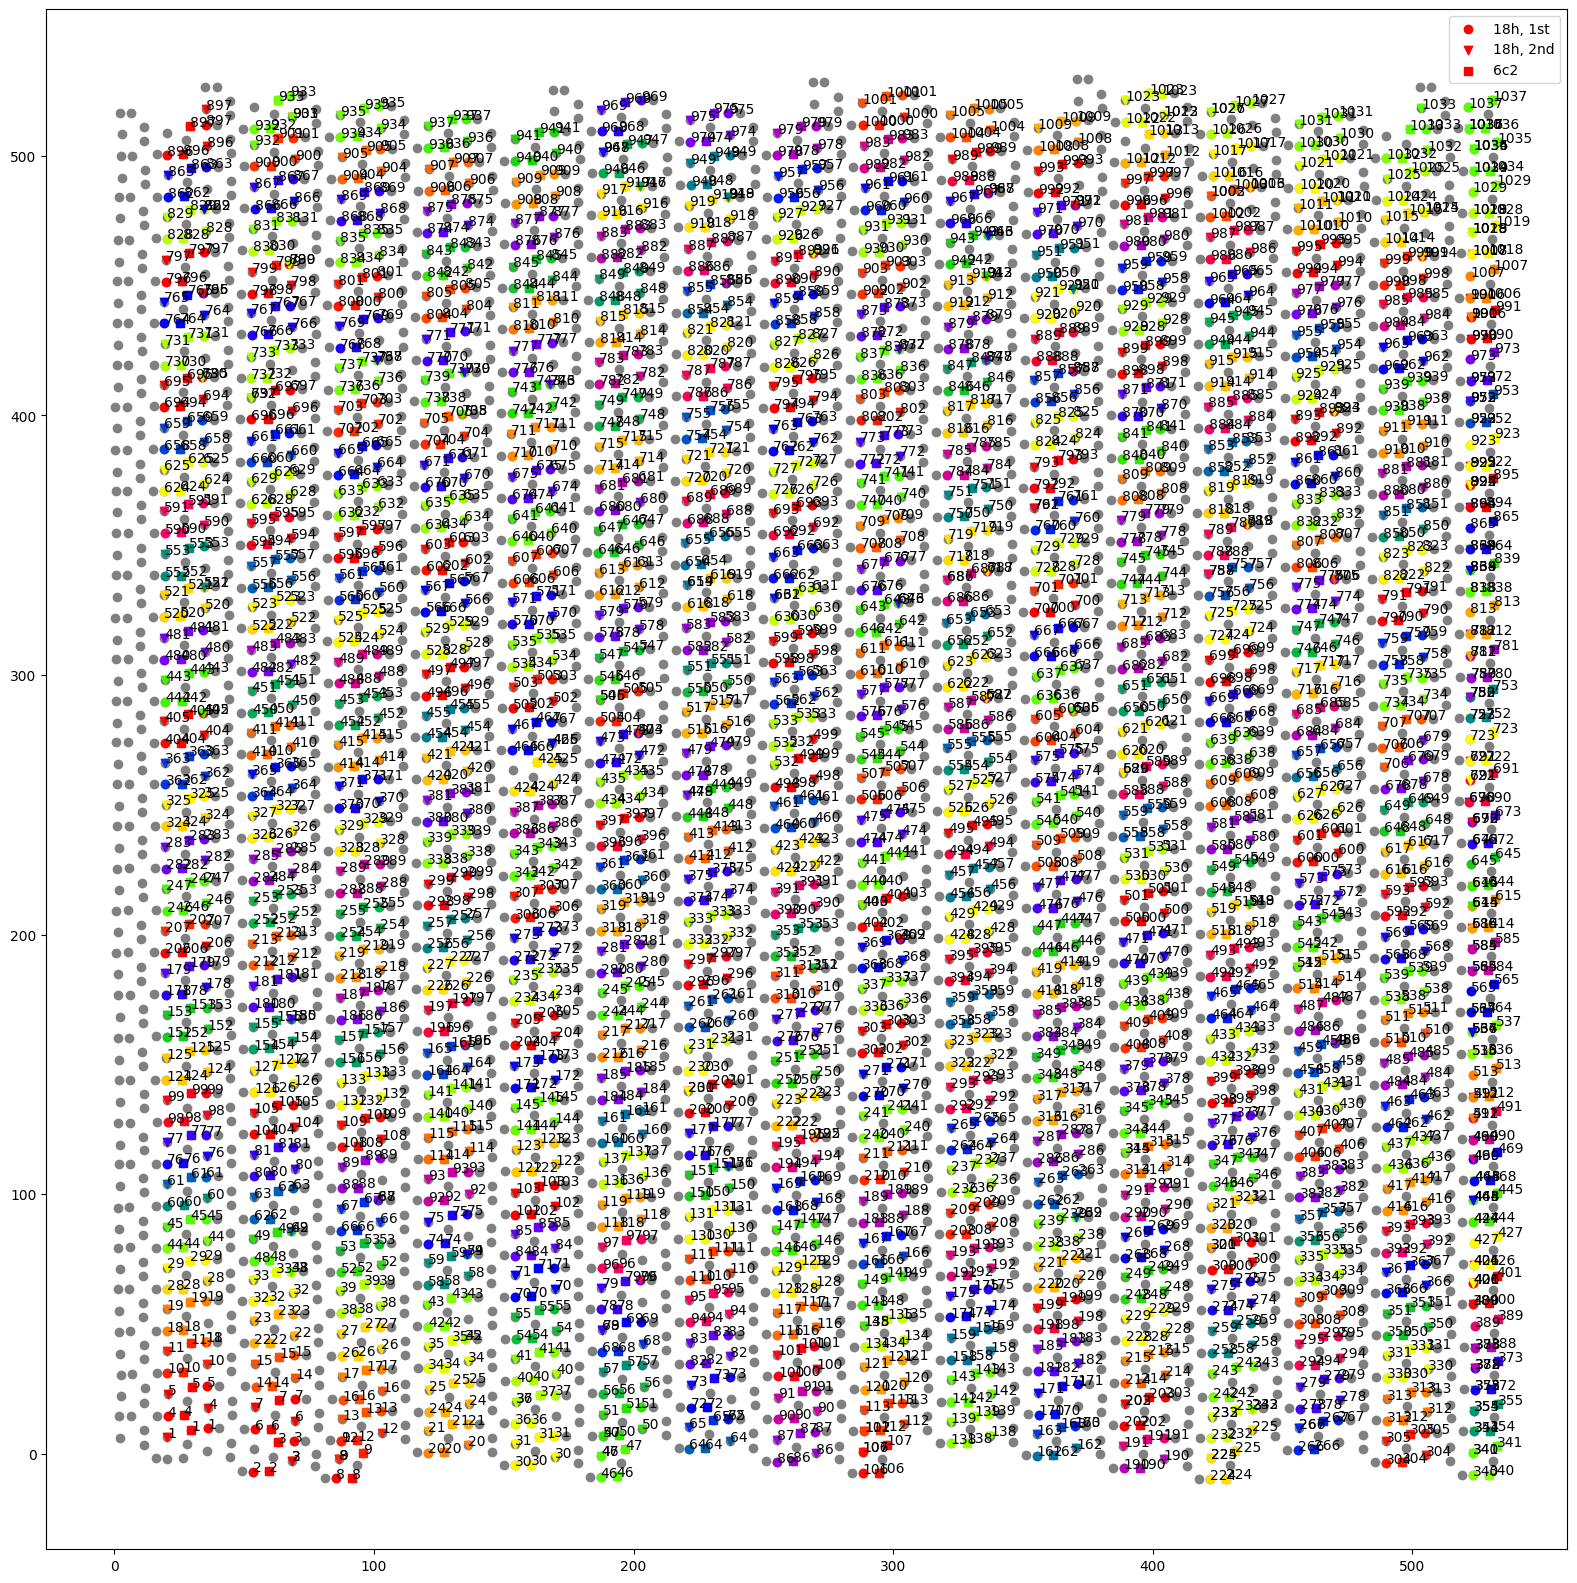

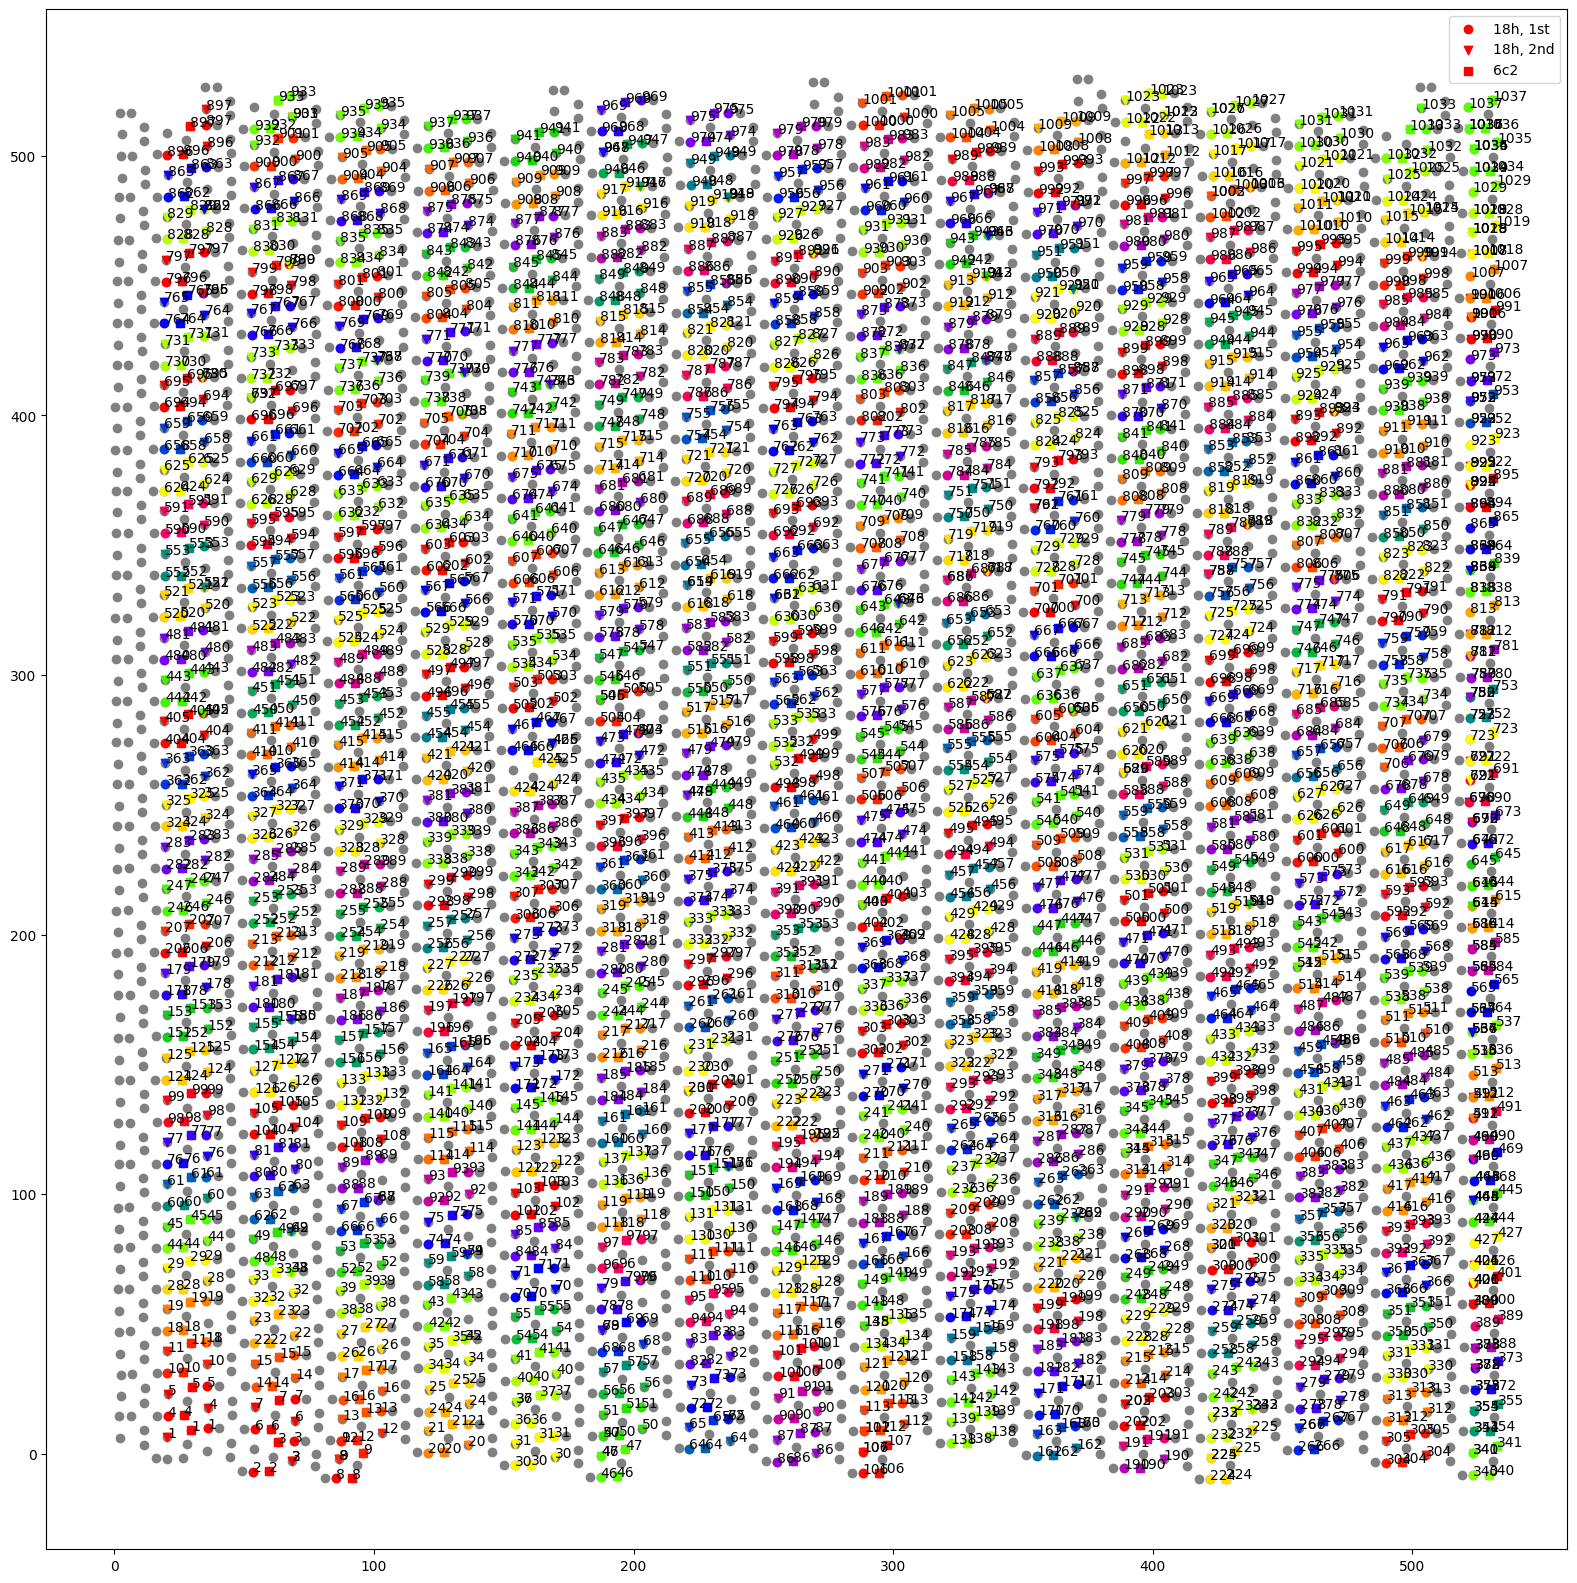

In [ ]:
import matplotlib as mpl

fixed_site = '3a'
selected_site = '6c2'

min_distances_m1_t = get_interplanarSpacings_wplot(fixed_site,
                                        selected_site,
                                        df_rot,mu_c_direction='x',
                                        # selected_motif='motif_1',
                                        max_distance_px=12,plotting=False)
min_distances_m2_t = get_interplanarSpacings_wplot(fixed_site,
                                        selected_site,
                                        df_rot,mu_c_direction='x',
                                        selected_motif='motif_2',
                                        max_distance_px=12)



fixed_site = '6c2'
selected_site = '18h'
min_distances_m1_tK = get_interplanarSpacings_wplot(fixed_site,
                                        selected_site,
                                        df_rot,mu_c_direction='x',
                                        # selected_motif='motif_1',
                                        max_distance_px=8,plotting=True,displacement_thresold = 1)
min_distances_m2_tK = get_interplanarSpacings_wplot(fixed_site,
                                        selected_site,
                                        df_rot,mu_c_direction='x',
                                        selected_motif='motif_2',
                                        max_distance_px=8,plotting=True)

min_distances_t = np.concatenate((min_distances_m1_t,min_distances_m2_t))
min_distances_tK = np.concatenate((min_distances_m1_tK,min_distances_m2_tK))


# print(min_distances_t.mean() * md['nm_per_pixel']* 10, 'Å')
# print(min_distances_t.std() * md['nm_per_pixel']* 10, 'Å')



## RWTH gpt becasue i am lazy
# Put them into a list for easy iteration
all_min_distances = [
    min_distances_t,
    min_distances_m1_t,
    # min_distances_m2_t,
    min_distances_tK,
    min_distances_m1_tK,
    # min_distances_m2_tK,
]


stats = []                     # each element will be (index, mean, std)
for idx, arr in enumerate(all_min_distances):
    mean_val = arr.mean()
    std_val  = np.std(arr, ddof=1)   # sample std‑deviation (ddof=1) – change to 0 for population
    stats.append((idx, mean_val, std_val))



array_names = ['d_t','d_t_m1','d_t_m2','d_tK','d_tK_m1','d_tK_m2']

output_path = results_folder.joinpath("min_distances_stats.txt")
with open(output_path, "w") as f:
    # Header line (optional, but handy for readability)
    f.write("array_index,mean,standard_deviation\n")
    # One line per array
    for idx, mean_val, std_val in stats:
        f.write(f"{array_names[idx]},{mean_val* md['nm_per_pixel']* 10:.6f},{std_val* md['nm_per_pixel']* 10:.6f}\n")

print(f"Statistics saved to '{output_path}'.")

In [30]:
min_distances_m1_tK

array([6.41009712, 6.14781189, 5.98163605, ..., 9.09082031, 6.17352295,
       9.11914062], shape=(1037,))

In [46]:
np.std(min_distances_m1_tK*md['nm_per_pixel']*10)

np.float64(0.1693533484768468)

In [31]:
# min_distances=np.concatenate((min_distances_m1,min_distances_m2))
# print(min_distances.mean() * md['nm_per_pixel']* 10, 'Å')
# print(min_distances.std() * md['nm_per_pixel']* 10, 'Å')

Text(0.5, 1.0, 'Motif 2')

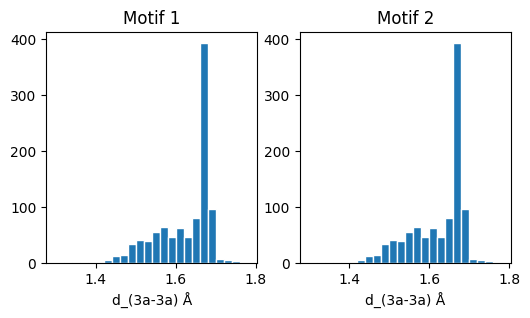

In [44]:
# Compare the distribution of dt_k values
fig,ax = plt.subplots(1,2,figsize=(6,3))
spacings = np.arange(1.3,1.8,0.02)
ax[0].hist(min_distances_m1_tK* md['nm_per_pixel']* 10 , spacings,edgecolor='white')
ax[1].hist(min_distances_m2_tK* md['nm_per_pixel']* 10,  spacings,edgecolor='white')#* md['nm_per_pixel']* 10
#print(min_distances.std() * md['nm_per_pixel']* 10, 'Å')
# min_distances
# plt.hist(
ax[0].set_xlabel(f"d_(3a-{selected_site}) Å")
ax[1].set_xlabel(f"d_(3a-{selected_site}) Å")
ax[0].set_title('Motif 1')
ax[1].set_title('Motif 2')
# ax[0].set_xlim(1.5,1.8)
# ax[1].set_xlim(1.5,1.8)

Text(0.5, 1.0, 'Motif 2')

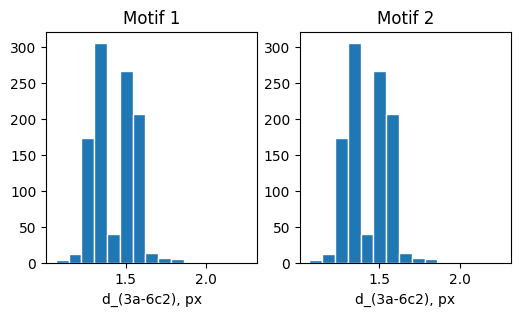

In [48]:
fig,ax = plt.subplots(1,2,figsize=(6,3))
ax[0].hist(min_distances_m1_t , bins=15,edgecolor='white')
ax[1].hist(min_distances_m2_t,  bins=15,edgecolor='white')#* md['nm_per_pixel']* 10
#print(min_distances.std() * md['nm_per_pixel']* 10, 'Å')
# min_distances
# plt.hist(
ax[0].set_xlabel(f"d_(3a-6c2), px")
ax[1].set_xlabel(f"d_(3a-6c2), px")
ax[0].set_title('Motif 1')
ax[1].set_title('Motif 2')

Text(0.5, 1.0, 'Motif 2')

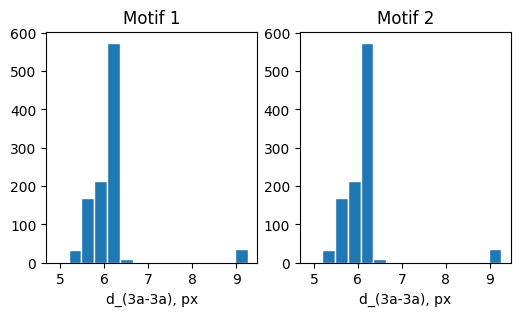

In [ ]:
fig,ax = plt.subplots(1,2,figsize=(6,3))
ax[0].hist(min_distances_m1_tK , bins=15,edgecolor='white')
ax[1].hist(min_distances_m2_tK,  bins=15,edgecolor='white')#* md['nm_per_pixel']* 10
#print(min_distances.std() * md['nm_per_pixel']* 10, 'Å')
# min_distances
# plt.hist(
ax[0].set_xlabel(f"d_(6c2-18h, px")
ax[1].set_xlabel(f"d_(6c2-18h), px")
ax[0].set_title('Motif 1')
ax[1].set_title('Motif 2')


Text(0.5, 1.0, 'Motif 2')

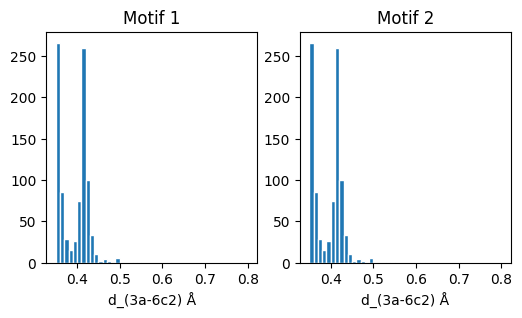

In [45]:
# Compare the distribution of dt_k values
fig,ax = plt.subplots(1,2,figsize=(6,3))
spacings = np.arange(0.35,0.8,0.01)
ax[0].hist(min_distances_m1_t* md['nm_per_pixel']* 10 , spacings,edgecolor='white')
ax[1].hist(min_distances_m2_t* md['nm_per_pixel']* 10,  spacings,edgecolor='white')#* md['nm_per_pixel']* 10
#print(min_distances.std() * md['nm_per_pixel']* 10, 'Å')
# min_distances
# plt.hist(
ax[0].set_xlabel(f"d_(3a-6c2) Å")
ax[1].set_xlabel(f"d_(3a-6c2) Å")
ax[0].set_title('Motif 1')
ax[1].set_title('Motif 2')
# ax[0].set_xlim(0.35,0.65)
# ax[1].set_xlim(0.35,0.65)

In [35]:
def get_interplanarSpacings_extended_filters(fixedPos,movingPos,df_rot,mu_c_direction='x',selected_motif='motif_1',max_distance_px=50,displacement_thresold = 1.5,max_dev_y=5 ):

    # df_rot = df_rot[df_rot['displacement']<displacement_thresold].reset_index()
    # df_rot = df_rot[df_rot['y']<500].reset_index()
    df_rot_3a = df_rot[df_rot['label_mu'] ==fixedPos]
    selected_site = movingPos
    diff_vals = np.zeros((len(df_rot_3a), len(df_rot)))
    diff_vals_y = np.zeros((len(df_rot_3a), len(df_rot)))
    diff_vals_x = np.zeros((len(df_rot_3a), len(df_rot)))
    
    # print(df_rot_3a)
    # print(df_rot)
    ## calculate euclididan distance between respetive sites with label fixedPos and movingPos
    for i in range(0, len(df_rot["y"].values)):
        print(df_rot.at[i,'label_mu'])
        print(df_rot.at[i,"motif_source"])
        if df_rot.at[i,"label_mu"]==selected_site:# and df_rot.at[i,"motif_source"]==selected_motif:
            y_3a = df_rot_3a["y"].values
            x_3a = df_rot_3a["x"].values
    
            y = df_rot.at[i, "y"]
            x = df_rot.at[i, "x"]
    
            diff_vals[:,i] = np.sqrt((x_3a - x)**2 + (y_3a -y )**2)
            diff_vals_y[:,i]  = np.abs((y_3a-y))
            diff_vals_x[:,i]  = np.abs((x_3a-x))
        else:
            diff_vals[:,i] = np.inf
            diff_vals_y[:,i]  =np.inf
            diff_vals_x[:,i]  =np.inf

    print(diff_vals)

    diff_vals = diff_vals[diff_vals_y<max_dev_y]
    diff_vals_x = diff_vals_x[diff_vals_y<max_dev_y]

    min_dist_indices = np.argsort(np.abs(diff_vals), 1)
    # print(min_dist_indices.shape)
    # print(np.abs(diff_vals[min_dist_indices]))

    if movingPos == fixedPos:
        print('same site calculation')
        
        closest_distances = min_dist_indices[:, 2]
        second_closest_distance = min_dist_indices[:, 3]
    else:
        closest_distances = min_dist_indices[:, 0]
        second_closest_distance = min_dist_indices[:, 1]

    ## calculate distance in x or y dircetion
    min_distance_list = []
    df_rot_3a = df_rot_3a.reset_index()
    for i in range(0, len(min_dist_indices)):
        x1 = diff_vals_x[closest_distances[i], mu_c_direction]
        x2 =diff_vals_x[second_closest_distance[i], mu_c_direction]
        # x_3a = df_rot_3a.at[i, mu_c_direction]
        min_distance_list.append(np.mean(x1,x2))
    
    min_distances = np.array(min_distance_list)
    min_distances = min_distances[min_distances<max_distance_px]
    return min_distances
    # plt.plot(min_distances)
    # min_distances.mean()

In [ ]:
np.std()

In [36]:
fixed_site = '3a'
selected_site = '3a'
min_distances = get_interplanarSpacings(fixed_site,
                                        selected_site,
                                        df_rot,mu_c_direction='x',
                                        selected_motif='motif_2',
                                        max_distance_px=50,
                                        displacement_thresold =3)

18h


KeyError: 'motif_source'

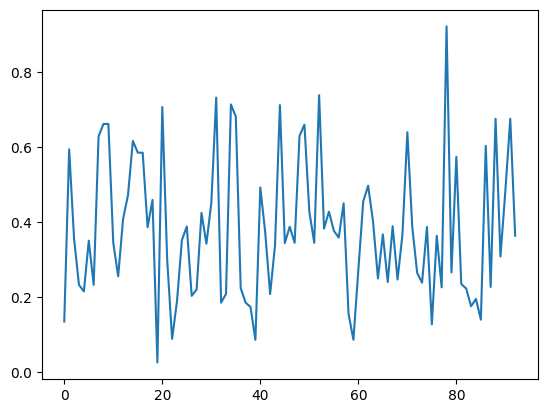

In [ ]:
plt.plot(min_distances)

## Debugging

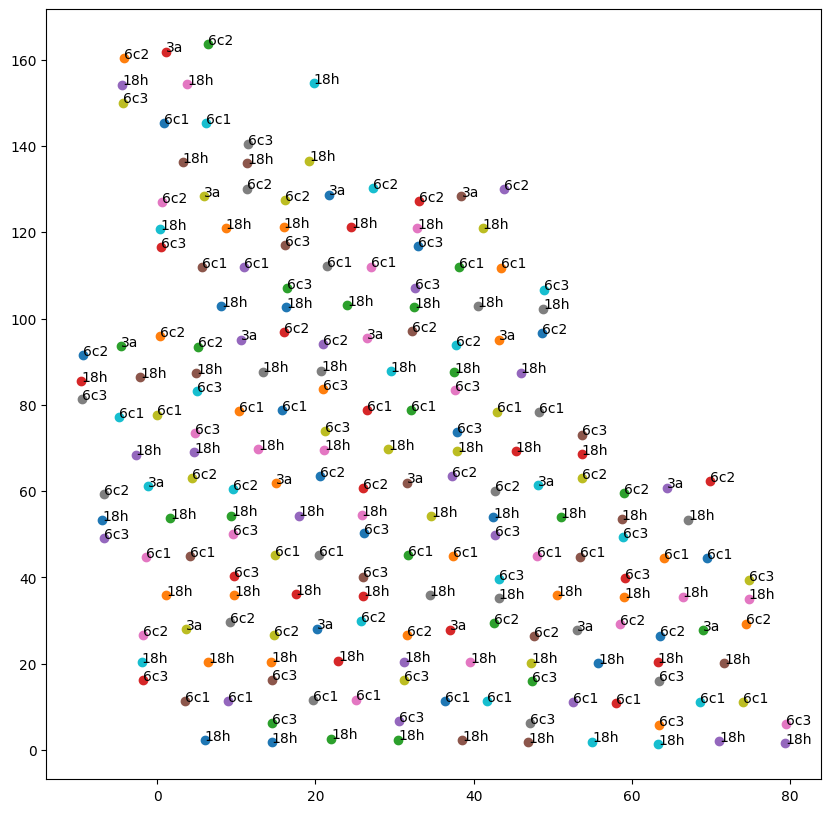

In [41]:
fig,ax = plt.subplots(figsize=(10,10))
for i in range(0,200):
    ax.scatter(df_rot.at[i,'y'].item(),df_rot.at[i,'x'].item())
    ax.text(df_rot.at[i,'y'].item(),df_rot.at[i,'x'].item(),str(df_rot.at[i,'label_mu']))#,str(i))

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29


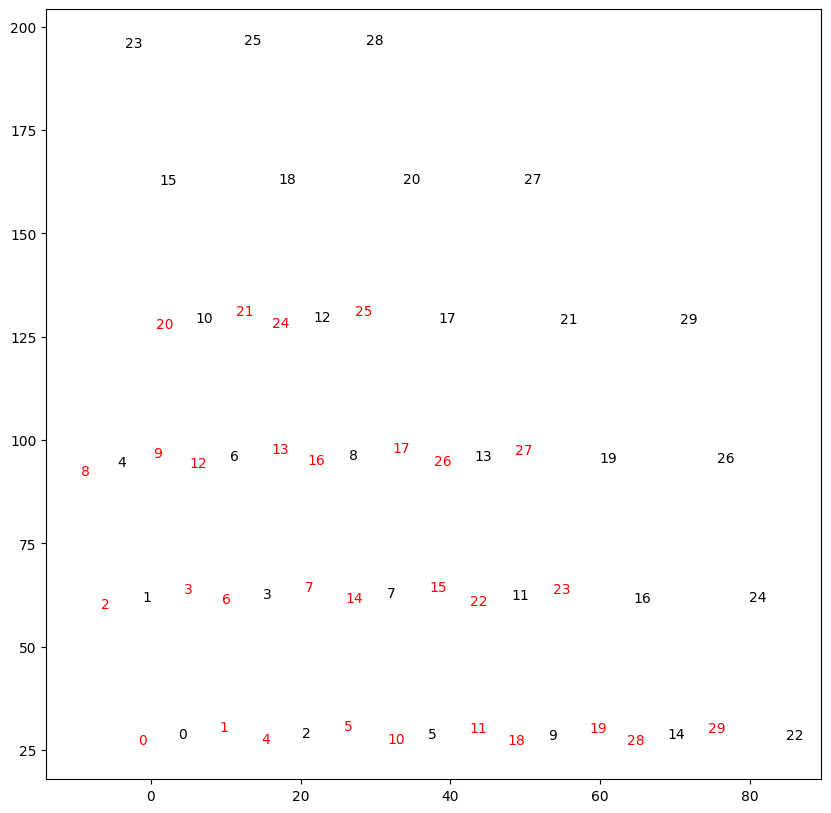

In [39]:
df_rot_3a = df_rot[df_rot['label_mu']=='3a'].reset_index()
fig,ax = plt.subplots(figsize=(10,10))
for i in range(0,30):#len(df_rot_3a)-1):
    print(str(i))
    ax.plot(df_rot_3a.at[i,'y'].item(),df_rot_3a.at[i,'x'].item())
    ax.text(df_rot_3a.at[i,'y'].item(),df_rot_3a.at[i,'x'].item(),str(i))#,str(i))
df_rot_18h = df_rot[df_rot['label_mu']=='6c2'].reset_index()
# fig,ax = plt.subplots(figsize=(10,10))
for i in range(0,30):#,len(df_rot_18h)-1):
    print(str(i))
    ax.plot(df_rot_18h.at[i,'y'].item(),df_rot_18h.at[i,'x'].item())
    ax.text(df_rot_18h.at[i,'y'].item(),df_rot_18h.at[i,'x'].item(),str(i),color='r')#,str(i))

In [ ]:
(df_rot_3a['x'].values[0]-df_rot_3a['x'].values[1])*3*md['nm_per_pixel']

np.float64(-0.005215187988361556)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

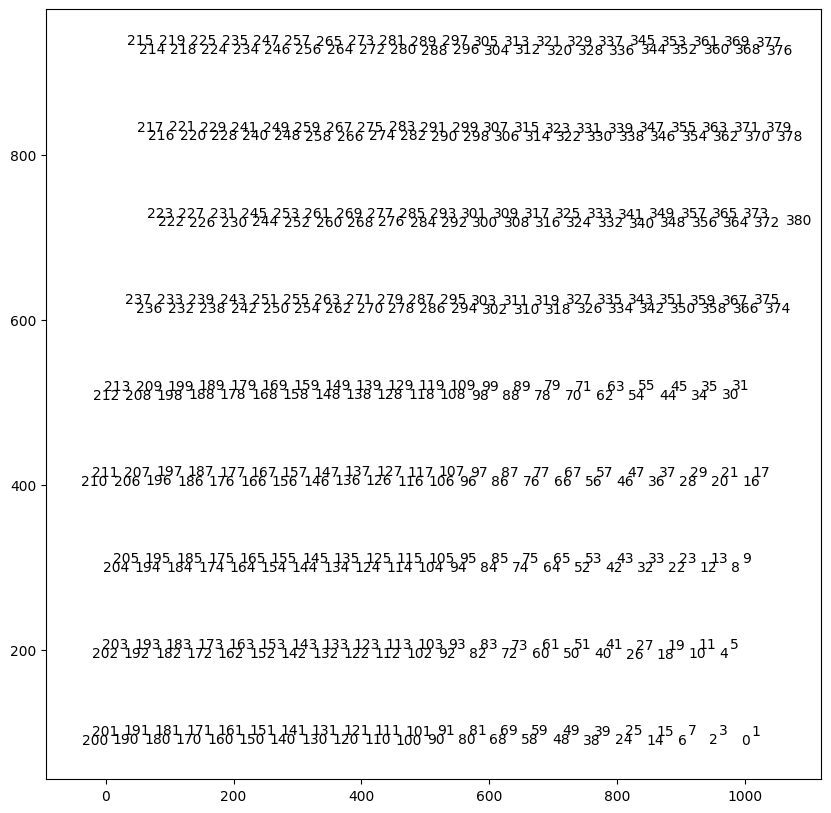

In [ ]:
df_rot_18h = df_rot[df_rot['label_mu']=='6c2'].reset_index()
fig,ax = plt.subplots(figsize=(10,10))
for i in range(0,len(df_rot_18h)-1):
    print(str(i))
    ax.plot(df_rot_18h.at[i,'y'].item(),df_rot_18h.at[i,'x'].item())
    ax.text(df_rot_18h.at[i,'y'].item(),df_rot_18h.at[i,'x'].item(),str(i))#,str(i))

In [ ]:
min_vals = np.nanmin(np.abs(diff_vals),1)
min_vals[[1,2,5,9,14,20,24,28,33,37,41,45,49]]


NameError: name 'diff_vals' is not defined